<a href="https://colab.research.google.com/github/chtzortzi-alt/Tzortzi_Loan_Approval/blob/main/Tzortzi_Loan_Approval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

In [28]:
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename, sep=";")

Saving loan_approval_dataset.csv to loan_approval_dataset (1).csv


In [29]:
df.columns = df.columns.str.strip()
df.columns.tolist()

['loan_id',
 'no_of_dependents',
 'education',
 'self_employed',
 'income_annum',
 'loan_amount',
 'loan_term',
 'cibil_score',
 'residential_assets_value',
 'commercial_assets_value',
 'luxury_assets_value',
 'bank_asset_value',
 'loan_status']

In [30]:
for column in df.select_dtypes(include="object").columns:
  df[column]=df[column].str.strip()

In [31]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head(20))
df.info()

Shape: (4269, 13)
Columns: ['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
5,6,0,Graduate,Yes,4800000,13500000,10,319,6800000,8300000,13700000,5100000,Rejected
6,7,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,Approved
7,8,2,Graduate,Yes,5700000,15000000,20,382,13200000,5700000,11800000,6000000,Rejected
8,9,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,Approved
9,10,5,Not Graduate,No,1100000,4300000,10,388,3200000,1400000,3300000,1600000,Rejected


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [32]:
print(df["loan_status"].value_counts())

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [33]:
numeric_features=df.select_dtypes(include="number").drop(
    columns=["loan_id"],errors="ignore"
)

status_summary=df.groupby("loan_status")[numeric_features.columns].median().T
status_summary

loan_status,Approved,Rejected
no_of_dependents,2.5,3.0
income_annum,5000000.0,5100000.0
loan_amount,14600000.0,14500000.0
loan_term,10.0,12.0
cibil_score,711.0,429.0
residential_assets_value,5400000.0,5900000.0
commercial_assets_value,3700000.0,3700000.0
luxury_assets_value,14400000.0,14800000.0
bank_asset_value,4500000.0,4600000.0


In [34]:
education_status=pd.crosstab(
    df["education"], df["loan_status"], normalize="index"
).round(3)

self_employment_status=pd.crosstab(
     df["self_employed"], df["loan_status"], normalize="index"
).round(3)

education_status, self_employment_status

(loan_status   Approved  Rejected
 education                       
 Graduate         0.625     0.375
 Not Graduate     0.620     0.380,
 loan_status    Approved  Rejected
 self_employed                    
 No                0.622     0.378
 Yes               0.622     0.378)

In [35]:
print("Shape:", df.shape)
print("\nMissing values per column:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("\nData types:")
print(df.dtypes)

Shape: (4269, 13)

Missing values per column:
loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Duplicate rows: 0

Data types:
loan_id                      int64
no_of_dependents             int64
education                   object
self_employed               object
income_annum                 int64
loan_amount                  int64
loan_term                    int64
cibil_score                  int64
residential_assets_value     int64
commercial_assets_value      int64
luxury_assets_value          int64
bank_asset_value             int64
loan_status                 object
dtype: object


In [36]:
numeric_features=df.select_dtypes(include="number").drop(
    columns=["loan_id"], errors="ignore"
)

numeric_features.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_dependents,4269.0,2.498712e+00,1.695910e+00,0.0,1.0,3.0,4.0,5.0
income_annum,4269.0,5.059124e+06,2.806840e+06,200000.0,2700000.0,5100000.0,7500000.0,9900000.0
loan_amount,4269.0,1.513345e+07,9.043363e+06,300000.0,7700000.0,14500000.0,21500000.0,39500000.0
loan_term,4269.0,1.090045e+01,5.709187e+00,2.0,6.0,10.0,16.0,20.0
cibil_score,4269.0,5.999361e+02,1.724304e+02,300.0,453.0,600.0,748.0,900.0
residential_assets_value,4269.0,7.472617e+06,6.503637e+06,-100000.0,2200000.0,5600000.0,11300000.0,29100000.0
commercial_assets_value,4269.0,4.973155e+06,4.388966e+06,0.0,1300000.0,3700000.0,7600000.0,19400000.0
luxury_assets_value,4269.0,1.512631e+07,9.103754e+06,300000.0,7500000.0,14600000.0,21700000.0,39200000.0
bank_asset_value,4269.0,4.976692e+06,3.250185e+06,0.0,2300000.0,4600000.0,7100000.0,14700000.0


In [37]:
(numeric_features==0).sum()

,0
no_of_dependents,712
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,45
commercial_assets_value,107
luxury_assets_value,0
bank_asset_value,8


In [38]:
status_summary=df.groupby("loan_status")[numeric_features.columns].agg(
    ["mean", "median", "std"]
).T

status_summary

loan_status                          Approved      Rejected
no_of_dependents         mean    2.474774e+00  2.538128e+00
                         median  2.500000e+00  3.000000e+00
                         std     1.695270e+00  1.696754e+00
income_annum             mean    5.025904e+06  5.113825e+06
                         median  5.000000e+06  5.100000e+06
                         std     2.827228e+06  2.772946e+06
loan_amount              mean    1.524725e+07  1.494606e+07
                         median  1.460000e+07  1.450000e+07
                         std     9.221696e+06  8.741390e+06
loan_term                mean    1.039759e+01  1.172846e+01
                         median  1.000000e+01  1.200000e+01
                         std     5.879523e+00  5.316127e+00
cibil_score              mean    7.034620e+02  4.294681e+02
                         median  7.110000e+02  4.290000e+02
                         std     1.252490e+02  7.840175e+01
residential_assets_value mean    7.399812e+06  7.592498e+06
                         median  5.400000e+06  5.900000e+06
                         std     6.501363e+06  6.507619e+06
commercial_assets_value  mean    5.001355e+06  4.926720e+06
                         median  3.700000e+06  3.700000e+06
                         std     4.390803e+06  4.386905e+06
luxury_assets_value      mean    1.501660e+07  1.530694e+07
                         median  1.440000e+07  1.480000e+07
                         std     9.154286e+06  9.019850e+06
bank_asset_value         mean    4.959526e+06  5.004960e+06
                         median  4.500000e+06  4.600000e+06
                         std     3.273718e+06  3.211871e+06

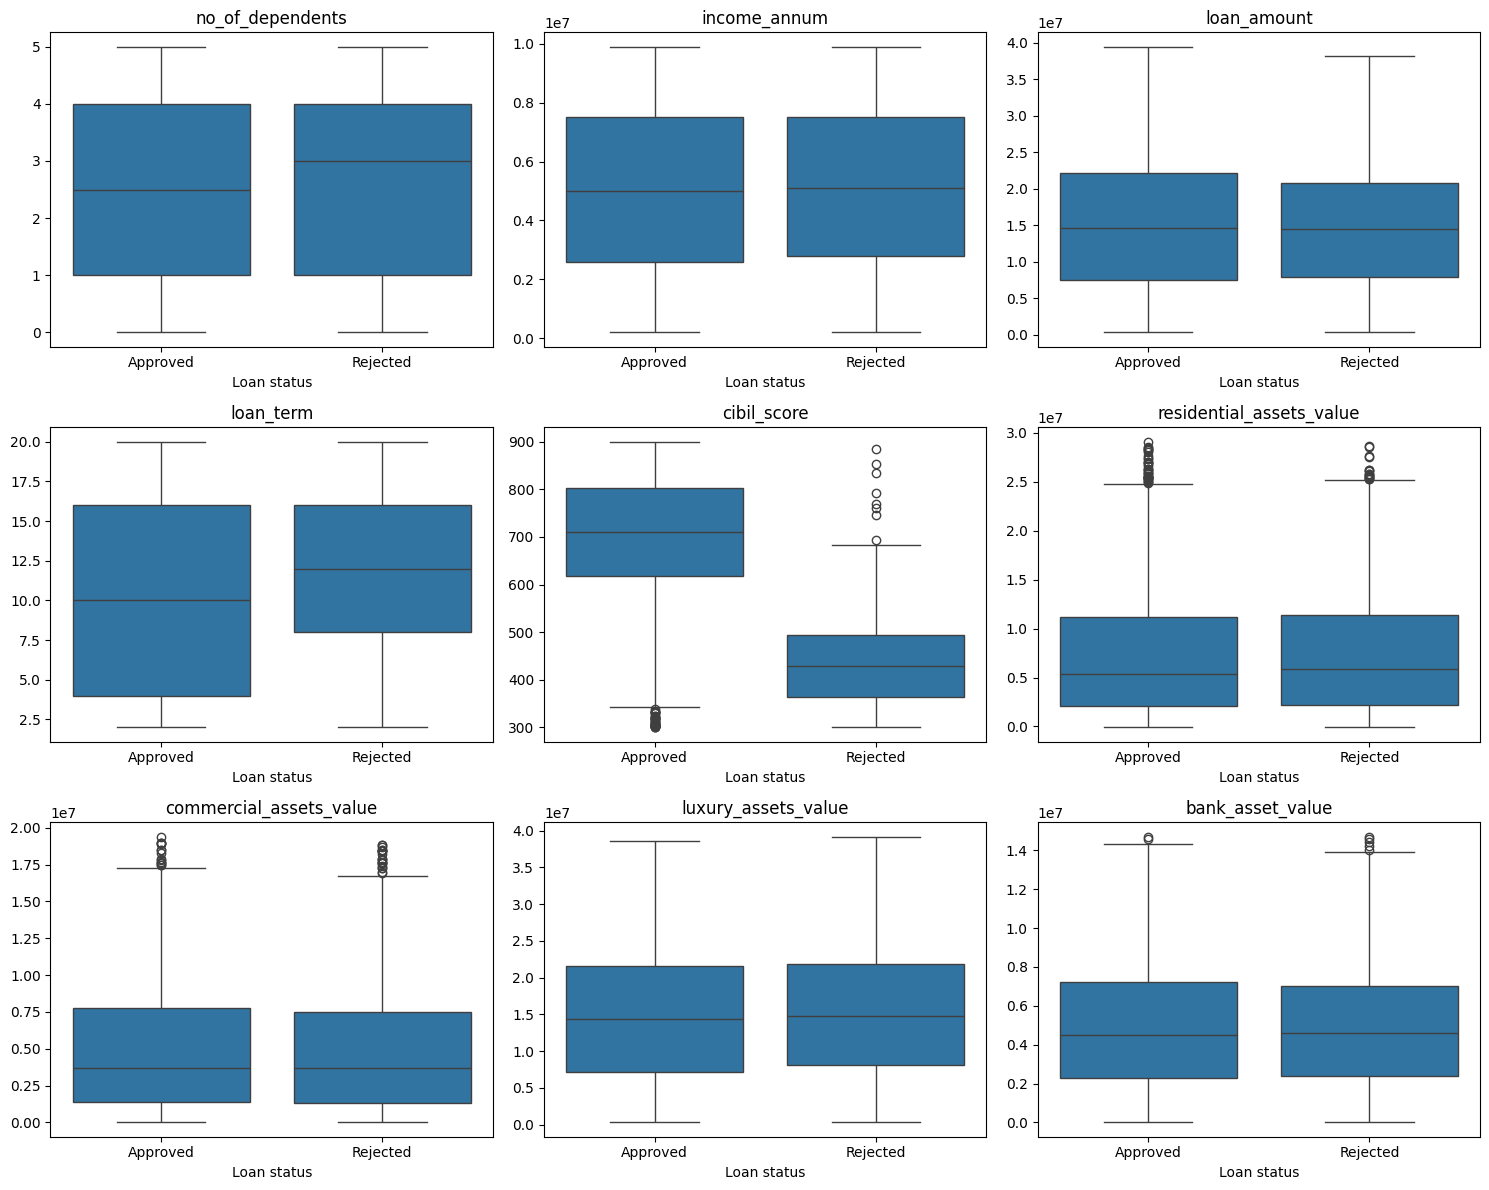

In [39]:
fig, axes=plt.subplots(3, 3, figsize=(15, 12))

for ax, column in zip(axes.flat, numeric_features.columns):
  sns.boxplot(data=df, x="loan_status", y=column, ax=ax)
  ax.set_title(column)
  ax.set_xlabel("Loan status")
  ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [40]:
categorical_features=df.select_dtypes(include="object").columns.drop(
    "loan_status", errors="ignore"
)

for column in categorical_features:
  print(f"\n{column}: counts")
  print(pd.crosstab(df[column], df["loan_status"]))

  print(f"\n{column}: proportions within each category")
  print(
      pd.crosstab(
          df[column],
          df["loan_status"],
          normalize="index"
      ).round(3)
  )


education: counts
loan_status   Approved  Rejected
education                       
Graduate          1339       805
Not Graduate      1317       808

education: proportions within each category
loan_status   Approved  Rejected
education                       
Graduate         0.625     0.375
Not Graduate     0.620     0.380

self_employed: counts
loan_status    Approved  Rejected
self_employed                    
No                 1318       801
Yes                1338       812

self_employed: proportions within each category
loan_status    Approved  Rejected
self_employed                    
No                0.622     0.378
Yes               0.622     0.378


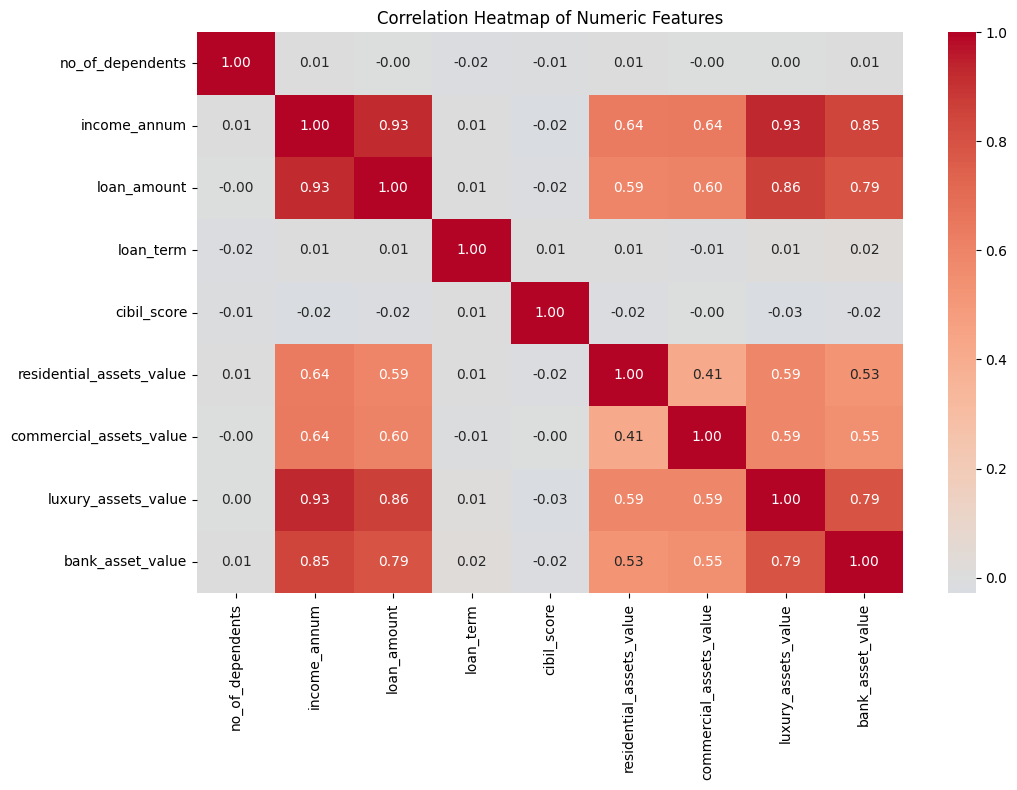

In [41]:
corrmatrix=numeric_features.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    corrmatrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

In [42]:
df.loc[
    df["residential_assets_value"]<0,
    ["loan_id", "residential_assets_value", "loan_status"]
]

,loan_id,residential_assets_value,loan_status
59,60,-100000,Approved
196,197,-100000,Approved
559,560,-100000,Rejected
702,703,-100000,Approved
737,738,-100000,Rejected
784,785,-100000,Approved
904,905,-100000,Approved
1089,1090,-100000,Rejected
1163,1164,-100000,Approved
1350,1351,-100000,Rejected


In [43]:
feature_ratings=pd.DataFrame([
    ["loan_id", "Not-important", "Identifies the record; does not describe the applicant or loan."],
    ["no_of_dependents", "Not-important", "Approved and rejected groups have very similar values."],
    ["education", "Not-important", "Approval proportions are nearly identical across categories."],
    ["self_employed", "Not-important", "Approval proportions are identical in the observed groups."],
    ["income_annum", "In-between", "Group values are close; strongly overlaps with loan amount and luxury assets."],
    ["loan_amount", "In-between", "Group values are close; strongly overlaps with income annum and asset measures."],
    ["loan_term", "In-between", "There's some group difference, but there's distribution overlap."],
    ["cibil_score", "Important", "Approved and rejected loans show a great difference in scores."],
    ["residential_assets_value", "In-between", "Group values are close; repeated -100000 values."],
    ["commercial_assets_value", "In-between", "Group values are close; overlap with other asset features."],
    ["luxury_assets_value", "In-between", "Group values are close; strong overlap with income annum."],
    ["bank_asset_value", "In-between", "Group values are close; overlap with other asset features."]
], columns=["Feature", "Suggested rating", "Reason"])

display(feature_ratings)

,Feature,Suggested rating,Reason
0,loan_id,Not-important,Identifies the record; does not describe the a...
1,no_of_dependents,Not-important,Approved and rejected groups have very similar...
2,education,Not-important,Approval proportions are nearly identical acro...
3,self_employed,Not-important,Approval proportions are identical in the obse...
4,income_annum,In-between,Group values are close; strongly overlaps with...
5,loan_amount,In-between,Group values are close; strongly overlaps with...
6,loan_term,In-between,"There's some group difference, but there's dis..."
7,cibil_score,Important,Approved and rejected loans show a great diffe...
8,residential_assets_value,In-between,Group values are close; repeated -100000 values.
9,commercial_assets_value,In-between,Group values are close; overlap with other ass...


In [44]:
rating_column=next(
    column
    for column in ["Rating", "Suggested rating"]
    if column in feature_ratings.columns
)

task3_table=feature_ratings.copy()

for rating in ["Important", "In-between", "Not-important"]:
  task3_table[rating]=task3_table[rating_column].eq(rating).map(
      {True: "yes", False: ""}
  )

task3_table=task3_table[
    ["Feature", "Important", "In-between", "Not-important", "Reason"]
]

display(task3_table)

,Feature,Important,In-between,Not-important,Reason
0,loan_id,,,yes,Identifies the record; does not describe the a...
1,no_of_dependents,,,yes,Approved and rejected groups have very similar...
2,education,,,yes,Approval proportions are nearly identical acro...
3,self_employed,,,yes,Approval proportions are identical in the obse...
4,income_annum,,yes,,Group values are close; strongly overlaps with...
5,loan_amount,,yes,,Group values are close; strongly overlaps with...
6,loan_term,,yes,,"There's some group difference, but there's dis..."
7,cibil_score,yes,,,Approved and rejected loans show a great diffe...
8,residential_assets_value,,yes,,Group values are close; repeated -100000 values.
9,commercial_assets_value,,yes,,Group values are close; overlap with other ass...
